# Detección de Fraude en Seguros (ANN Profunda)
Este cuaderno utiliza el dataset real **`carclaims.csv`**.



### 0. Configuración del Entorno y Dependencias
Preparamos el terreno importando las librerías necesarias. Eliminamos la generación de datos sintéticos para forzarnos a usar la base de datos real.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, f1_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight
import os

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo de ejecución: {device}')


Dispositivo de ejecución: cpu


### 1. Carga de Datos y EDA
Verificamos que el archivo original esté presente e inspeccionamos los datos para entender el entorno.

Cargando dataset real carclaims.csv...

--- Información del Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Month                 15420 non-null  object
 1   WeekOfMonth           15420 non-null  int64 
 2   DayOfWeek             15420 non-null  object
 3   Make                  15420 non-null  object
 4   AccidentArea          15420 non-null  object
 5   DayOfWeekClaimed      15420 non-null  object
 6   MonthClaimed          15420 non-null  object
 7   WeekOfMonthClaimed    15420 non-null  int64 
 8   Sex                   15420 non-null  object
 9   MaritalStatus         15420 non-null  object
 10  Age                   15420 non-null  int64 
 11  Fault                 15420 non-null  object
 12  PolicyType            15420 non-null  object
 13  VehicleCategory       15420 non-null  object
 14  VehiclePrice  

,WeekOfMonth,WeekOfMonthClaimed,Age,PolicyNumber,RepNumber,Deductible,DriverRating,Year
count,15420.00,15420.00,15420.00,15420.00,15420.00,15420.00,15420.00,15420.00
mean,2.79,2.69,39.86,7710.50,8.48,407.70,2.49,1994.87
std,1.29,1.26,13.49,4451.51,4.60,43.95,1.12,0.80
min,1.00,1.00,0.00,1.00,1.00,300.00,1.00,1994.00
25%,2.00,2.00,31.00,3855.75,5.00,400.00,1.00,1994.00
50%,3.00,3.00,38.00,7710.50,8.00,400.00,2.00,1995.00
75%,4.00,4.00,48.00,11565.25,12.00,400.00,3.00,1996.00
max,5.00,5.00,80.00,15420.00,16.00,700.00,4.00,1996.00


/var/folders/nv/2vg5q8t90j16svvsqd8ln3v00000gn/T/ipykernel_25258/3905540995.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='FraudFound', palette='Set2')


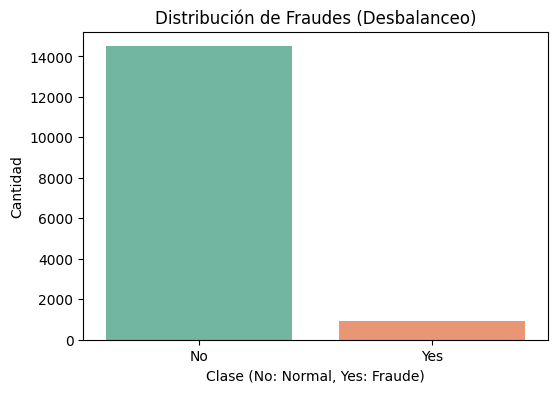

In [ ]:
file_path = 'carclaims.csv'
if not os.path.exists(file_path):
    raise FileNotFoundError(f"¡Error! No se encontró el archivo '{file_path}'. Asegúrate de subirlo a tu entorno de Colab.")

print("Cargando dataset real carclaims.csv...")
df = pd.read_csv(file_path)

print("\n--- Información del Dataset ---")
print(df.info())

print("\n--- Estadísticas Descriptivas ---")
display(df.describe().round(2))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='FraudFound', palette='Set2')
plt.title('Distribución de Fraudes (Desbalanceo)')
plt.xlabel('Clase (No: Normal, Yes: Fraude)')
plt.ylabel('Cantidad')
plt.show()


### 2. Preprocesamiento Seguro (Arreglo del Data Leakage)
Aquí es donde ocurrió el problema de fuga de datos. Al crear la variable objetivo `target`, la dejamos accidentalmente dentro del paquete de datos `X` que la red usa para aprender. Ahora, **eliminamos explícitamente tanto `FraudFound` como `target` de las características de entrada**.

In [ ]:
df_processed = df.copy()

# Convertimos la variable objetivo a binaria
df_processed['target'] = df_processed['FraudFound'].map({'No': 0, 'Yes': 1})

# SOLUCIÓN AL DATA LEAKAGE:
# Nos aseguramos de borrar tanto la columna de texto original como la nueva columna numérica.
# También borramos PolicyNumber para que la red no memorice pólizas individuales.
columns_to_drop = ['FraudFound', 'target']
if 'PolicyNumber' in df_processed.columns:
    columns_to_drop.append('PolicyNumber')

# Separamos Características (X) y Etiquetas (y) de forma limpia
X_raw = df_processed.drop(columns=columns_to_drop)
y = df_processed['target'].values

# One-Hot Encoding para las variables de texto (Mes, Marca de coche, etc.)
X_encoded = pd.get_dummies(X_raw, drop_first=True)
X = X_encoded.astype(np.float32).values

print(f"Forma de la matriz X (sin trampa): {X.shape}")


Forma de la matriz X (sin trampa): (15420, 123)


### 3. División de Datos y Escalado
Mantenemos la división estricta Train/Val/Test y el escalado posterior para que la red no vea el futuro.

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

train_loader = DataLoader(TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long)), batch_size=128, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.long)), batch_size=128, shuffle=False)
test_loader = DataLoader(TensorDataset(torch.tensor(X_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.long)), batch_size=128, shuffle=False)


### 4. Arquitectura y Compensación del Desbalanceo
Estructura profunda con pesos matemáticos para darle importancia al 6% de fraudes reales.

In [ ]:
"""
class ANNDeepAnomalyDetector(nn.Module):
    def __init__(self, input_size):
        super(ANNDeepAnomalyDetector, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 2)
        )
"""
class ANNDeepAnomalyDetector(nn.Module):
    def __init__(self, input_size):
        super(ANNDeepAnomalyDetector, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.LayerNorm(64),          # NUEVO
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.LayerNorm(32),          # NUEVO
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 16),
            nn.LayerNorm(16),          # NUEVO
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(16, 2),
        )

    def forward(self, x):
        return self.network(x)

model = ANNDeepAnomalyDetector(input_size=X_train.shape[1]).to(device)

classes = np.unique(y_train)
class_weights = compute_class_weight( class_weight="balanced", classes=classes, y=y_train )
class_weights = torch.tensor( class_weights, dtype=torch.float32 ).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

#optimizer = optim.Adam(model.parameters(), lr=1e-4)


optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-2,
)

print(model)


ANNDeepAnomalyDetector(
  (network): Sequential(
    (0): Linear(in_features=123, out_features=64, bias=True)
    (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): LayerNorm((16,), eps=1e-05, elementwise_affine=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=16, out_features=2, bias=True)
  )
)


### 5. Entrenamiento y Monitorización
Entrenamos guardando el progreso en el diccionario `history`.

In [ ]:
"""
epochs = 200
history = {'train_loss': [], 'val_loss': []}

for epoch in range(epochs):
    model.train()
    train_loss = 0
    for data, target in train_loader:
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for data, target in val_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            loss = criterion(output, target)
            val_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)
    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")
    """


'\nepochs = 200\nhistory = {\'train_loss\': [], \'val_loss\': []}\n\nfor epoch in range(epochs):\n    model.train()\n    train_loss = 0\n    for data, target in train_loader:\n        data, target = data.to(device), target.to(device)\n        optimizer.zero_grad()\n        output = model(data)\n        loss = criterion(output, target)\n        loss.backward()\n        optimizer.step()\n        train_loss += loss.item()\n\n    model.eval()\n    val_loss = 0\n    with torch.no_grad():\n        for data, target in val_loader:\n            data, target = data.to(device), target.to(device)\n            output = model(data)\n            loss = criterion(output, target)\n            val_loss += loss.item()\n\n    avg_train_loss = train_loss / len(train_loader)\n    avg_val_loss = val_loss / len(val_loader)\n    history[\'train_loss\'].append(avg_train_loss)\n    history[\'val_loss\'].append(avg_val_loss)\n    print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {a

Fold 1/10 | Epoch [1/200] | Train Loss: 0.7324 | Val Loss: 0.6798 | F1: 0.135 | Recall: 0.716 | LR próxima época: 1.00e-04
Fold 1/10 | Epoch [2/200] | Train Loss: 0.7036 | Val Loss: 0.6737 | F1: 0.157 | Recall: 0.473 | LR próxima época: 1.00e-04
Fold 1/10 | Epoch [3/200] | Train Loss: 0.6893 | Val Loss: 0.6712 | F1: 0.143 | Recall: 0.311 | LR próxima época: 1.00e-04
Fold 1/10 | Epoch [4/200] | Train Loss: 0.6874 | Val Loss: 0.6667 | F1: 0.151 | Recall: 0.324 | LR próxima época: 1.00e-04
Fold 1/10 | Epoch [5/200] | Train Loss: 0.6771 | Val Loss: 0.6603 | F1: 0.185 | Recall: 0.419 | LR próxima época: 1.00e-04
Fold 1/10 | Epoch [6/200] | Train Loss: 0.6724 | Val Loss: 0.6512 | F1: 0.176 | Recall: 0.473 | LR próxima época: 1.00e-04
Fold 1/10 | Epoch [7/200] | Train Loss: 0.6709 | Val Loss: 0.6455 | F1: 0.188 | Recall: 0.527 | LR próxima época: 1.00e-04
Fold 1/10 | Epoch [8/200] | Train Loss: 0.6596 | Val Loss: 0.6357 | F1: 0.190 | Recall: 0.568 | LR próxima época: 1.00e-04
Fold 1/10 | Epoc

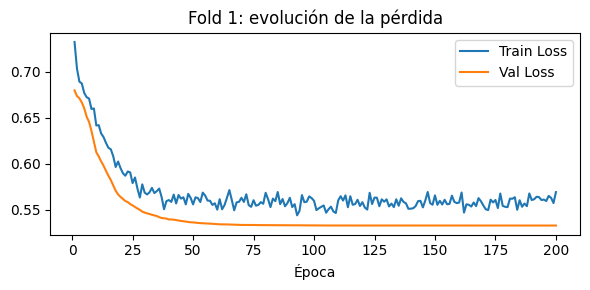

Fold 2/10 | Epoch [1/200] | Train Loss: 0.7332 | Val Loss: 0.6876 | F1: 0.134 | Recall: 0.716 | LR próxima época: 1.00e-04
Fold 2/10 | Epoch [2/200] | Train Loss: 0.6996 | Val Loss: 0.6810 | F1: 0.155 | Recall: 0.459 | LR próxima época: 1.00e-04
Fold 2/10 | Epoch [3/200] | Train Loss: 0.6925 | Val Loss: 0.6783 | F1: 0.138 | Recall: 0.297 | LR próxima época: 1.00e-04
Fold 2/10 | Epoch [4/200] | Train Loss: 0.6908 | Val Loss: 0.6731 | F1: 0.147 | Recall: 0.311 | LR próxima época: 1.00e-04
Fold 2/10 | Epoch [5/200] | Train Loss: 0.6899 | Val Loss: 0.6671 | F1: 0.187 | Recall: 0.419 | LR próxima época: 1.00e-04
Fold 2/10 | Epoch [6/200] | Train Loss: 0.6784 | Val Loss: 0.6584 | F1: 0.193 | Recall: 0.500 | LR próxima época: 1.00e-04
Fold 2/10 | Epoch [7/200] | Train Loss: 0.6632 | Val Loss: 0.6493 | F1: 0.205 | Recall: 0.541 | LR próxima época: 1.00e-04
Fold 2/10 | Epoch [8/200] | Train Loss: 0.6648 | Val Loss: 0.6404 | F1: 0.199 | Recall: 0.581 | LR próxima época: 1.00e-04
Fold 2/10 | Epoc

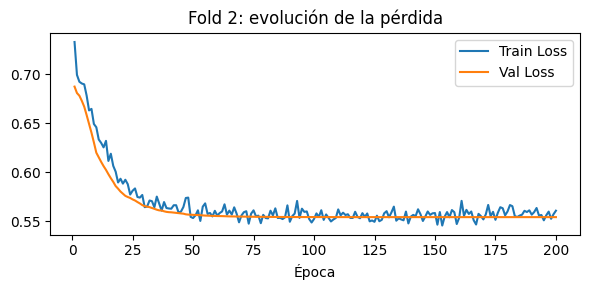

Fold 3/10 | Epoch [1/200] | Train Loss: 0.7293 | Val Loss: 0.6903 | F1: 0.120 | Recall: 0.622 | LR próxima época: 1.00e-04
Fold 3/10 | Epoch [2/200] | Train Loss: 0.7043 | Val Loss: 0.6857 | F1: 0.115 | Recall: 0.324 | LR próxima época: 1.00e-04
Fold 3/10 | Epoch [3/200] | Train Loss: 0.6899 | Val Loss: 0.6807 | F1: 0.117 | Recall: 0.270 | LR próxima época: 1.00e-04
Fold 3/10 | Epoch [4/200] | Train Loss: 0.6904 | Val Loss: 0.6760 | F1: 0.129 | Recall: 0.284 | LR próxima época: 1.00e-04
Fold 3/10 | Epoch [5/200] | Train Loss: 0.6805 | Val Loss: 0.6699 | F1: 0.151 | Recall: 0.351 | LR próxima época: 1.00e-04
Fold 3/10 | Epoch [6/200] | Train Loss: 0.6856 | Val Loss: 0.6620 | F1: 0.166 | Recall: 0.432 | LR próxima época: 1.00e-04
Fold 3/10 | Epoch [7/200] | Train Loss: 0.6735 | Val Loss: 0.6551 | F1: 0.171 | Recall: 0.446 | LR próxima época: 1.00e-04
Fold 3/10 | Epoch [8/200] | Train Loss: 0.6607 | Val Loss: 0.6459 | F1: 0.179 | Recall: 0.500 | LR próxima época: 1.00e-04
Fold 3/10 | Epoc

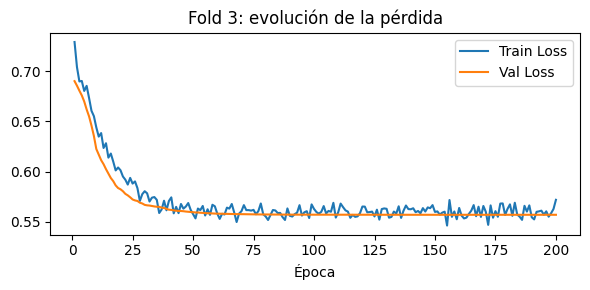

Fold 4/10 | Epoch [1/200] | Train Loss: 0.7275 | Val Loss: 0.6965 | F1: 0.113 | Recall: 0.622 | LR próxima época: 1.00e-04
Fold 4/10 | Epoch [2/200] | Train Loss: 0.7052 | Val Loss: 0.6874 | F1: 0.131 | Recall: 0.419 | LR próxima época: 1.00e-04
Fold 4/10 | Epoch [3/200] | Train Loss: 0.6949 | Val Loss: 0.6829 | F1: 0.148 | Recall: 0.338 | LR próxima época: 1.00e-04
Fold 4/10 | Epoch [4/200] | Train Loss: 0.6819 | Val Loss: 0.6771 | F1: 0.154 | Recall: 0.324 | LR próxima época: 1.00e-04
Fold 4/10 | Epoch [5/200] | Train Loss: 0.6861 | Val Loss: 0.6709 | F1: 0.172 | Recall: 0.419 | LR próxima época: 1.00e-04
Fold 4/10 | Epoch [6/200] | Train Loss: 0.6740 | Val Loss: 0.6643 | F1: 0.179 | Recall: 0.459 | LR próxima época: 1.00e-04
Fold 4/10 | Epoch [7/200] | Train Loss: 0.6697 | Val Loss: 0.6554 | F1: 0.198 | Recall: 0.527 | LR próxima época: 1.00e-04
Fold 4/10 | Epoch [8/200] | Train Loss: 0.6638 | Val Loss: 0.6455 | F1: 0.191 | Recall: 0.581 | LR próxima época: 1.00e-04
Fold 4/10 | Epoc

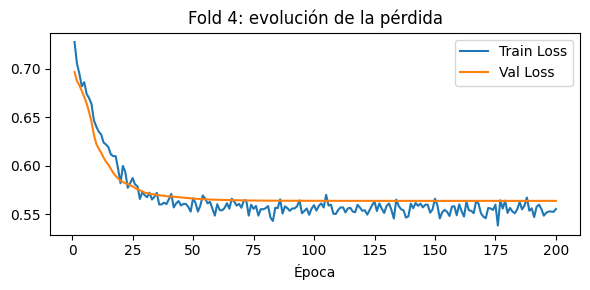

Fold 5/10 | Epoch [1/200] | Train Loss: 0.7253 | Val Loss: 0.6865 | F1: 0.123 | Recall: 0.635 | LR próxima época: 1.00e-04
Fold 5/10 | Epoch [2/200] | Train Loss: 0.7026 | Val Loss: 0.6796 | F1: 0.146 | Recall: 0.432 | LR próxima época: 1.00e-04
Fold 5/10 | Epoch [3/200] | Train Loss: 0.6962 | Val Loss: 0.6760 | F1: 0.164 | Recall: 0.405 | LR próxima época: 1.00e-04
Fold 5/10 | Epoch [4/200] | Train Loss: 0.6889 | Val Loss: 0.6714 | F1: 0.176 | Recall: 0.392 | LR próxima época: 1.00e-04
Fold 5/10 | Epoch [5/200] | Train Loss: 0.6895 | Val Loss: 0.6663 | F1: 0.197 | Recall: 0.459 | LR próxima época: 1.00e-04
Fold 5/10 | Epoch [6/200] | Train Loss: 0.6760 | Val Loss: 0.6578 | F1: 0.212 | Recall: 0.554 | LR próxima época: 1.00e-04
Fold 5/10 | Epoch [7/200] | Train Loss: 0.6692 | Val Loss: 0.6487 | F1: 0.203 | Recall: 0.568 | LR próxima época: 1.00e-04
Fold 5/10 | Epoch [8/200] | Train Loss: 0.6624 | Val Loss: 0.6370 | F1: 0.208 | Recall: 0.662 | LR próxima época: 1.00e-04
Fold 5/10 | Epoc

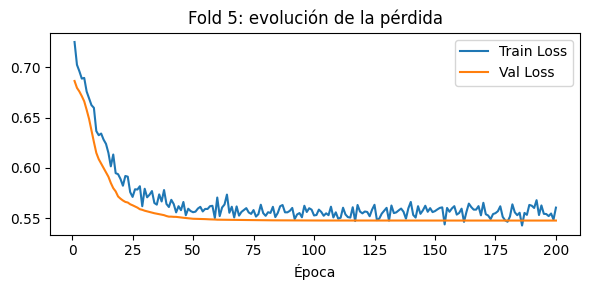

Fold 6/10 | Epoch [1/200] | Train Loss: 0.7319 | Val Loss: 0.6971 | F1: 0.109 | Recall: 0.581 | LR próxima época: 1.00e-04
Fold 6/10 | Epoch [2/200] | Train Loss: 0.6934 | Val Loss: 0.6920 | F1: 0.131 | Recall: 0.365 | LR próxima época: 1.00e-04
Fold 6/10 | Epoch [3/200] | Train Loss: 0.6901 | Val Loss: 0.6852 | F1: 0.124 | Recall: 0.284 | LR próxima época: 1.00e-04
Fold 6/10 | Epoch [4/200] | Train Loss: 0.6839 | Val Loss: 0.6777 | F1: 0.139 | Recall: 0.324 | LR próxima época: 1.00e-04
Fold 6/10 | Epoch [5/200] | Train Loss: 0.6844 | Val Loss: 0.6705 | F1: 0.154 | Recall: 0.378 | LR próxima época: 1.00e-04
Fold 6/10 | Epoch [6/200] | Train Loss: 0.6851 | Val Loss: 0.6635 | F1: 0.171 | Recall: 0.432 | LR próxima época: 1.00e-04
Fold 6/10 | Epoch [7/200] | Train Loss: 0.6667 | Val Loss: 0.6538 | F1: 0.182 | Recall: 0.514 | LR próxima época: 1.00e-04
Fold 6/10 | Epoch [8/200] | Train Loss: 0.6625 | Val Loss: 0.6405 | F1: 0.196 | Recall: 0.635 | LR próxima época: 1.00e-04
Fold 6/10 | Epoc

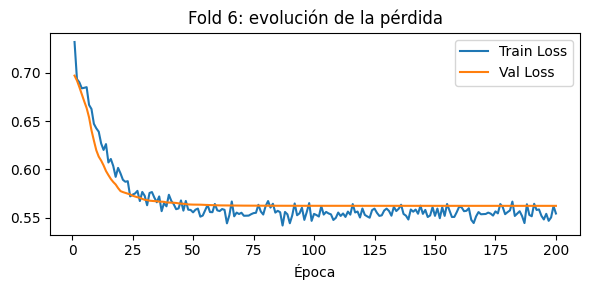

Fold 7/10 | Epoch [1/200] | Train Loss: 0.7286 | Val Loss: 0.6997 | F1: 0.121 | Recall: 0.589 | LR próxima época: 1.00e-04
Fold 7/10 | Epoch [2/200] | Train Loss: 0.7058 | Val Loss: 0.6931 | F1: 0.107 | Recall: 0.342 | LR próxima época: 1.00e-04
Fold 7/10 | Epoch [3/200] | Train Loss: 0.7023 | Val Loss: 0.6890 | F1: 0.129 | Recall: 0.315 | LR próxima época: 1.00e-04
Fold 7/10 | Epoch [4/200] | Train Loss: 0.6880 | Val Loss: 0.6840 | F1: 0.131 | Recall: 0.288 | LR próxima época: 1.00e-04
Fold 7/10 | Epoch [5/200] | Train Loss: 0.6853 | Val Loss: 0.6762 | F1: 0.158 | Recall: 0.370 | LR próxima época: 1.00e-04
Fold 7/10 | Epoch [6/200] | Train Loss: 0.6766 | Val Loss: 0.6691 | F1: 0.172 | Recall: 0.411 | LR próxima época: 1.00e-04
Fold 7/10 | Epoch [7/200] | Train Loss: 0.6737 | Val Loss: 0.6599 | F1: 0.195 | Recall: 0.534 | LR próxima época: 1.00e-04
Fold 7/10 | Epoch [8/200] | Train Loss: 0.6586 | Val Loss: 0.6509 | F1: 0.198 | Recall: 0.575 | LR próxima época: 1.00e-04
Fold 7/10 | Epoc

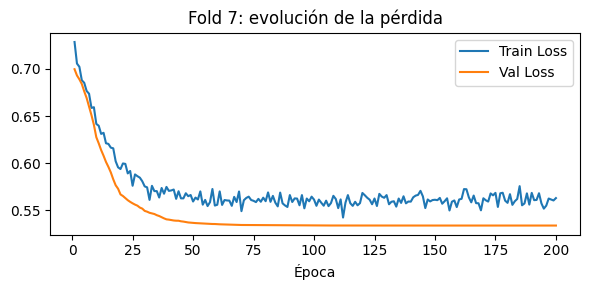

Fold 8/10 | Epoch [1/200] | Train Loss: 0.7217 | Val Loss: 0.6950 | F1: 0.116 | Recall: 0.644 | LR próxima época: 1.00e-04
Fold 8/10 | Epoch [2/200] | Train Loss: 0.6977 | Val Loss: 0.6858 | F1: 0.127 | Recall: 0.425 | LR próxima época: 1.00e-04
Fold 8/10 | Epoch [3/200] | Train Loss: 0.6936 | Val Loss: 0.6803 | F1: 0.141 | Recall: 0.397 | LR próxima época: 1.00e-04
Fold 8/10 | Epoch [4/200] | Train Loss: 0.6888 | Val Loss: 0.6766 | F1: 0.155 | Recall: 0.397 | LR próxima época: 1.00e-04
Fold 8/10 | Epoch [5/200] | Train Loss: 0.6793 | Val Loss: 0.6700 | F1: 0.168 | Recall: 0.466 | LR próxima época: 1.00e-04
Fold 8/10 | Epoch [6/200] | Train Loss: 0.6815 | Val Loss: 0.6622 | F1: 0.171 | Recall: 0.507 | LR próxima época: 1.00e-04
Fold 8/10 | Epoch [7/200] | Train Loss: 0.6653 | Val Loss: 0.6521 | F1: 0.164 | Recall: 0.521 | LR próxima época: 1.00e-04
Fold 8/10 | Epoch [8/200] | Train Loss: 0.6660 | Val Loss: 0.6428 | F1: 0.175 | Recall: 0.575 | LR próxima época: 1.00e-04
Fold 8/10 | Epoc

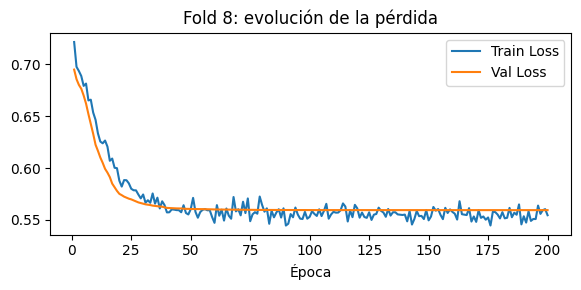

Fold 9/10 | Epoch [1/200] | Train Loss: 0.7294 | Val Loss: 0.6899 | F1: 0.131 | Recall: 0.649 | LR próxima época: 1.00e-04
Fold 9/10 | Epoch [2/200] | Train Loss: 0.7070 | Val Loss: 0.6839 | F1: 0.142 | Recall: 0.446 | LR próxima época: 1.00e-04
Fold 9/10 | Epoch [3/200] | Train Loss: 0.6899 | Val Loss: 0.6835 | F1: 0.174 | Recall: 0.365 | LR próxima época: 1.00e-04
Fold 9/10 | Epoch [4/200] | Train Loss: 0.6849 | Val Loss: 0.6793 | F1: 0.179 | Recall: 0.351 | LR próxima época: 1.00e-04
Fold 9/10 | Epoch [5/200] | Train Loss: 0.6750 | Val Loss: 0.6748 | F1: 0.188 | Recall: 0.392 | LR próxima época: 1.00e-04
Fold 9/10 | Epoch [6/200] | Train Loss: 0.6750 | Val Loss: 0.6673 | F1: 0.183 | Recall: 0.446 | LR próxima época: 1.00e-04
Fold 9/10 | Epoch [7/200] | Train Loss: 0.6681 | Val Loss: 0.6602 | F1: 0.187 | Recall: 0.500 | LR próxima época: 1.00e-04
Fold 9/10 | Epoch [8/200] | Train Loss: 0.6520 | Val Loss: 0.6525 | F1: 0.188 | Recall: 0.527 | LR próxima época: 1.00e-04
Fold 9/10 | Epoc

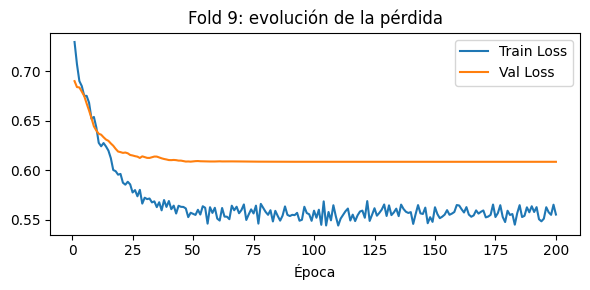

Fold 10/10 | Epoch [1/200] | Train Loss: 0.7308 | Val Loss: 0.6967 | F1: 0.123 | Recall: 0.662 | LR próxima época: 1.00e-04
Fold 10/10 | Epoch [2/200] | Train Loss: 0.6991 | Val Loss: 0.6888 | F1: 0.142 | Recall: 0.432 | LR próxima época: 1.00e-04
Fold 10/10 | Epoch [3/200] | Train Loss: 0.6976 | Val Loss: 0.6840 | F1: 0.129 | Recall: 0.297 | LR próxima época: 1.00e-04
Fold 10/10 | Epoch [4/200] | Train Loss: 0.6873 | Val Loss: 0.6784 | F1: 0.131 | Recall: 0.284 | LR próxima época: 1.00e-04
Fold 10/10 | Epoch [5/200] | Train Loss: 0.6796 | Val Loss: 0.6673 | F1: 0.192 | Recall: 0.500 | LR próxima época: 1.00e-04
Fold 10/10 | Epoch [6/200] | Train Loss: 0.6712 | Val Loss: 0.6553 | F1: 0.201 | Recall: 0.568 | LR próxima época: 1.00e-04
Fold 10/10 | Epoch [7/200] | Train Loss: 0.6657 | Val Loss: 0.6404 | F1: 0.211 | Recall: 0.622 | LR próxima época: 1.00e-04
Fold 10/10 | Epoch [8/200] | Train Loss: 0.6586 | Val Loss: 0.6284 | F1: 0.222 | Recall: 0.676 | LR próxima época: 1.00e-04
Fold 10/

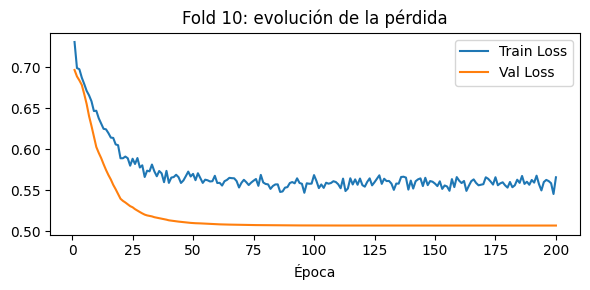


Validación cruzada: métricas de la última época


,Precision,Recall,F1,AUC
Fold,,,,
1,0.1363,0.8378,0.2344,0.7889
2,0.1305,0.7973,0.2243,0.7838
3,0.1280,0.7838,0.2201,0.7747
4,0.1232,0.8243,0.2144,0.7683
5,0.1261,0.8108,0.2182,0.7794
6,0.1245,0.8243,0.2163,0.7699
7,0.1279,0.8356,0.2218,0.7928
8,0.1242,0.8082,0.2153,0.7729
9,0.1182,0.6757,0.2012,0.7521



Media y desviación entre folds


,Precision,Recall,F1,AUC
mean,0.1277,0.8117,0.2207,0.7809
std,0.0061,0.0602,0.0109,0.0197



Entrenamiento final con el train original
Final | Epoch [1/200] | Train Loss: 0.7275 | Val Loss: 0.6948 | F1: 0.124 | Recall: 0.581 | LR próxima época: 1.00e-04
Final | Epoch [2/200] | Train Loss: 0.7059 | Val Loss: 0.6893 | F1: 0.128 | Recall: 0.366 | LR próxima época: 1.00e-04
Final | Epoch [3/200] | Train Loss: 0.6890 | Val Loss: 0.6840 | F1: 0.122 | Recall: 0.280 | LR próxima época: 1.00e-04
Final | Epoch [4/200] | Train Loss: 0.6860 | Val Loss: 0.6767 | F1: 0.141 | Recall: 0.323 | LR próxima época: 1.00e-04
Final | Epoch [5/200] | Train Loss: 0.6760 | Val Loss: 0.6697 | F1: 0.159 | Recall: 0.355 | LR próxima época: 1.00e-04
Final | Epoch [6/200] | Train Loss: 0.6719 | Val Loss: 0.6585 | F1: 0.201 | Recall: 0.527 | LR próxima época: 1.00e-04
Final | Epoch [7/200] | Train Loss: 0.6649 | Val Loss: 0.6490 | F1: 0.194 | Recall: 0.527 | LR próxima época: 1.00e-04
Final | Epoch [8/200] | Train Loss: 0.6616 | Val Loss: 0.6365 | F1: 0.187 | Recall: 0.559 | LR próxima época: 1.00e-04
Final

In [ ]:
# NUEVO: imports para validación cruzada y métricas.
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import recall_score, precision_score

epochs = 200
n_folds = 10

# NUEVO: reutilizar la arquitectura y el optimizador ya definidos.
ClaseModelo = type(model)
ClaseOptimizador = type(optimizer)
opciones_optimizer = optimizer.defaults.copy()
opciones_optimizer.pop("decoupled_weight_decay", None)

batch_size = train_loader.batch_size


def reiniciar_modelo(y_entrenamiento):
    """Crear un modelo desde cero y calcular pesos solo con su train."""
    torch.manual_seed(42)

    nuevo_modelo = ClaseModelo(
        input_size=X_train.shape[1]
    ).to(device)

    pesos = compute_class_weight(
        class_weight="balanced",
        classes=np.array([0, 1]),
        y=y_entrenamiento,
    )
    pesos = torch.tensor(
        pesos, dtype=torch.float32, device=device
    )

    nuevo_criterion = nn.CrossEntropyLoss(weight=pesos)
    nuevo_optimizer = ClaseOptimizador(
        nuevo_modelo.parameters(), **opciones_optimizer
    )

    return nuevo_modelo, nuevo_optimizer, nuevo_criterion


def entrenar(model, optimizer, criterion,
             train_loader, val_loader, etiqueta):

    # Bucle original dentro de una función para poder repetirlo.
    history = {
        "train_loss": [],
        "val_loss": [],
        "val_f1": [],
        "val_recall": [],
    }
    """
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
                optimizer,
                mode="min",
                factor=0.5,
                patience=3,
                threshold=1e-3,
                threshold_mode="abs",
                min_lr=1e-8,
            )
    """
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer,
        step_size=10,
        gamma=0.5,
        )
    for epoch in range(epochs):
        model.train()
        train_loss, train_weight = 0.0, 0.0

        for data, target in train_loader:
            data, target = data.to(device), target.to(device)

            optimizer.zero_grad()
            output = model(data)

            # Permite usar también la SNN del otro notebook.
            if output.ndim == 3:
                output = output.sum(dim=0)

            loss = criterion(output, target)
            loss.backward()
            optimizer.step()

            # Acumulación correcta de la pérdida ponderada.
            peso_batch = criterion.weight[target].sum().item()
            train_loss += loss.item() * peso_batch
            train_weight += peso_batch

        model.eval()
        val_loss, val_weight = 0.0, 0.0
        y_true, y_pred, y_probs = [], [], []

        with torch.no_grad():
            for data, target in val_loader:
                data, target = data.to(device), target.to(device)
                output = model(data)

                if output.ndim == 3:
                    output = output.sum(dim=0)

                loss = criterion(output, target)

                peso_batch = criterion.weight[target].sum().item()
                val_loss += loss.item() * peso_batch
                val_weight += peso_batch

                # NUEVO: recoger métricas de validación por época.
                y_true.extend(target.cpu().numpy())
                y_pred.extend(output.argmax(dim=1).cpu().numpy())
                y_probs.extend(
                    torch.softmax(output.double(), dim=1)[:, 1]
                    .cpu().numpy()
                )

        avg_train_loss = train_loss / train_weight
        avg_val_loss = val_loss / val_weight
        #avanzamos el scheduler
        #scheduler.step(avg_val_loss)
        scheduler.step()

        f1 = f1_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)

        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        history["val_f1"].append(f1)
        history["val_recall"].append(recall)

        print(
            f"{etiqueta} | Epoch [{epoch+1}/{epochs}] | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f} | "
            f"F1: {f1:.3f} | Recall: {recall:.3f}"
            f" | LR próxima época: {optimizer.param_groups[0]['lr']:.2e}"
        )

    # Métricas correspondientes a la ÚLTIMA época.
    metricas = {
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall,
        "F1": f1,
        "AUC": roc_auc_score(y_true, y_probs),
    }

    return history, metricas


# NUEVO: recuperar los datos de train antes de su escalado.
# Cada fold tendrá un escalador ajustado solo con su propio train.
# El scaler original y el test_loader permanecen disponibles.
X_cv = scaler.inverse_transform(X_train)
y_cv = np.asarray(y_train)

cv = StratifiedKFold(
    n_splits=n_folds,
    shuffle=True,
    random_state=42,
)

histories_cv = {}
metricas_cv = []

for fold, (idx_train, idx_val) in enumerate(
    cv.split(X_cv, y_cv), start=1
):
    scaler_fold = StandardScaler()
    Xtr = scaler_fold.fit_transform(X_cv[idx_train])
    Xva = scaler_fold.transform(X_cv[idx_val])

    train_loader_fold = DataLoader(
        TensorDataset(
            torch.tensor(Xtr, dtype=torch.float32),
            torch.tensor(y_cv[idx_train], dtype=torch.long),
        ),
        batch_size=batch_size,
        shuffle=True,
    )

    val_loader_fold = DataLoader(
        TensorDataset(
            torch.tensor(Xva, dtype=torch.float32),
            torch.tensor(y_cv[idx_val], dtype=torch.long),
        ),
        batch_size=batch_size,
        shuffle=False,
    )

    model_fold, optimizer_fold, criterion_fold = reiniciar_modelo(
        y_cv[idx_train]
    )

    history_fold, metricas_fold = entrenar(
        model_fold,
        optimizer_fold,
        criterion_fold,
        train_loader_fold,
        val_loader_fold,
        f"Fold {fold}/{n_folds}",
    )

    histories_cv[fold] = history_fold
    metricas_cv.append({"Fold": fold, **metricas_fold})

    plt.figure(figsize=(6, 3))
    plt.plot(
        range(1, epochs + 1),
        history_fold["train_loss"],
        label="Train Loss",
    )
    plt.plot(
        range(1, epochs + 1),
        history_fold["val_loss"],
        label="Val Loss",
    )
    plt.title(f"Fold {fold}: evolución de la pérdida")
    plt.xlabel("Época")
    plt.legend()
    plt.tight_layout()
    plt.show()

resultados_cv = pd.DataFrame(metricas_cv).set_index("Fold")

print("\nValidación cruzada: métricas de la última época")
display(resultados_cv.round(4))

print("\nMedia y desviación entre folds")
display(resultados_cv.agg(["mean", "std"]).round(4))


# NUEVO: entrenamiento final con TODO el train original.
# Deja model e history preparados para la celda de evaluación original.
print("\nEntrenamiento final con el train original")

model, optimizer, criterion = reiniciar_modelo(y_train)

history, metricas_finales_val = entrenar(
    model,
    optimizer,
    criterion,
    train_loader,
    val_loader,
    "Final",
)

## Seleccionar el umbral que maximice el f1 score de fraude

In [ ]:
import numpy as np
import torch
from sklearn.metrics import precision_recall_curve


def seleccionar_umbral_f1(modelo, val_loader, dispositivo):
    modelo.eval()
    y_true, y_scores = [], []

    with torch.no_grad():
        for data, target in val_loader:
            output = modelo(data.to(dispositivo))

            # SNN: acumular spikes. ANN: conservar logits.
            if output.ndim == 3:
                output = output.sum(dim=0)

            scores = torch.softmax(
                output.double(), dim=1
            )[:, 1]

            y_true.extend(target.cpu().numpy())
            y_scores.extend(scores.cpu().numpy())

    precision, recall, thresholds = precision_recall_curve(
        y_true, y_scores
    )

    # El último punto de la curva no tiene umbral asociado.
    f1 = (
        2 * precision[:-1] * recall[:-1]
        / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    )

    idx = int(np.argmax(f1))
    umbral = float(thresholds[idx])

    print(f"Umbral elegido: {umbral:.6f}")
    print(
        f"Selección en validación | F1: {f1[idx]:.4f} | "
        f"Precisión: {precision[idx]:.4f} | "
        f"Recall: {recall[idx]:.4f}"
    )

    return umbral


umbral = seleccionar_umbral_f1(model, val_loader, device)

Umbral elegido: 0.716894
Selección en validación | F1: 0.2476 | Precisión: 0.1757 | Recall: 0.4194


### 6. Evaluación de Rendimiento Real
Generamos los reportes sobre los datos de Test para ver el comportamiento del modelo en la realidad y la dificultad que refleja.

--- Reporte de Clasificación Real ---
              precision    recall  f1-score   support

      Normal       0.96      0.85      0.90      1450
      Fraude       0.16      0.45      0.24        92

    accuracy                           0.83      1542
   macro avg       0.56      0.65      0.57      1542
weighted avg       0.91      0.83      0.86      1542

F1-Score (Fraude): 0.2363
Área bajo la curva ROC (AUC): 0.7843


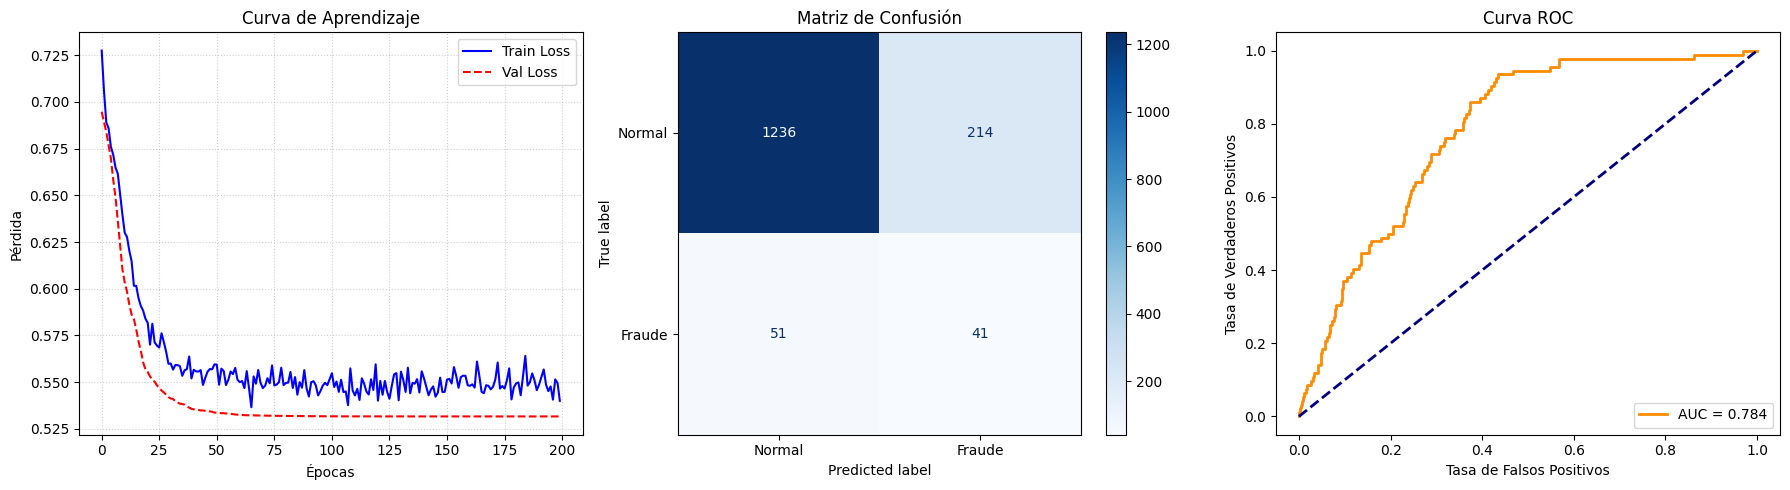

In [ ]:
def evaluar_modelo(modelo, dataloader, dispositivo):
    modelo.eval()
    y_true, y_pred, y_probs = [], [], []

    with torch.no_grad():
        for data, target in dataloader:
            data = data.to(dispositivo)
            output = modelo(data)
            if output.ndim == 3:
                output = output.sum(dim=0)

            probs = torch.softmax(output.double(), dim=1)[:, 1]
            preds = (probs >= umbral).long()

            y_true.extend(target.numpy())
            y_pred.extend(preds.cpu().numpy())
            y_probs.extend(probs.cpu().numpy())

    print("--- Reporte de Clasificación Real ---")
    print(classification_report(y_true, y_pred, target_names=["Normal", "Fraude"]))

    f1 = f1_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_probs)
    print(f"F1-Score (Fraude): {f1:.4f}")
    print(f"Área bajo la curva ROC (AUC): {roc_auc:.4f}")

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Curva de Pérdida
    axes[0].plot(history['train_loss'], label='Train Loss', color='blue')
    axes[0].plot(history['val_loss'], label='Val Loss', color='red', linestyle='--')
    axes[0].set_title('Curva de Aprendizaje')
    axes[0].set_xlabel('Épocas')
    axes[0].set_ylabel('Pérdida')
    axes[0].legend()
    axes[0].grid(True, linestyle=':', alpha=0.6)

    # 2. Matriz
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Fraude'])
    disp.plot(ax=axes[1], cmap='Blues')
    axes[1].set_title('Matriz de Confusión')

    # 3. ROC
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    axes[2].plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.3f}')
    axes[2].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    axes[2].set_title('Curva ROC')
    axes[2].set_xlabel('Tasa de Falsos Positivos')
    axes[2].set_ylabel('Tasa de Verdaderos Positivos')
    axes[2].legend(loc="lower right")

    plt.tight_layout()
    plt.show()

evaluar_modelo(model, test_loader, device)
